# Fig. 7a: neural manifolds of the ground truth and of the sorted populations (evoked model)

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel a of the paper: low-dimensional (PCA) manifolds of the responses of the ground truth neurons and of the sorted single-units of each spike sorter to 360 stimulus directions. Source data and svg are saved in figures/8_source_data/fig7a/.

**method (as in the paper's notebook fig7_A_pca_manifolds_revised.ipynb)**
* 1-hour biophysical simulation of the evoked regime (20 kHz): 36 simulation files, each with 10 stimulus directions, 360 directions x 50 repeated trials of 200 ms
* response of a unit to a trial: its spike count in the stimulus window; responses of the population = units x trials (18,000 trials)
* populations: all 1,836 ground truth neurons; the sorted single-units of Kilosort 4, 3, 2.5, 2, Kilosort and Herdingspikes (units labelled as single-units in `dataset/01_intermediate/analysis/sorting_quality/sorting_quality_evoked_1h.csv`); the multiunit threshold crossing of the 202 recording sites in the cortex (negative peaks of the whitened traces beyond 5 times the noise level; the 182 sites outside the cortex are excluded)
* **bottom row**: PCA (3 components) of the responses of the trials (each point is a trial), coordinates divided by the largest absolute coordinate; **top row**: PCA with 2 components, points averaged over the repeated trials of each direction (360 points); colour: stimulus direction (hsv colormap)

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
import spikeinterface as si
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)

# custom package
from sklearn.decomposition import PCA
from src.nodes.task import task

# paths
GT_PATH = "dataset/00_raw/ground_truth_npx_evoked"
SORTINGS_PATH = "dataset/01_intermediate/sorting/npx_evoked/"     # 1-hour sortings of the evoked simulation (Tesla V100, 20 kHz), from the dandi archive
SORTINGS = {"KS4": "SortingKS4", "KS3": "SortingKS3", "KS2.5": "SortingKS2_5", "KS2": "SortingKS2", "KS": "SortingKS", "HS": "SortingHerdingspikes"}
TC_PATH = "dataset/01_intermediate/sorting/npx_evoked/SortingTC"      # multiunit threshold crossing (src/pipes/sorting/npx_evoked/full/threshold_crossing.py)
QUALITY_PATH = "dataset/01_intermediate/analysis/sorting_quality/sorting_quality_evoked_1h.csv"     # sorted single-units of the 1-hour sortings

# stimulus: 360 directions x 50 repeated trials
SAMPLE_DIR = np.arange(0, 360, 1)

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

## Neural responses to the stimulus directions

In [2]:
%%time

# trials of the 360 directions and their direction labels
trial = task.get_direction_trials(SAMPLE_DIR)
direction = task.get_stimulus_labels()[trial].astype(float)

# task epochs (ms)
task_pm = task.get_task_parameters(start_delay=500, n_orientations=10, n_repeats=50, stimulus_duration=200, n_simulations=36)
stimulus_intervals_ms = task.get_stimulus_intervals_ms(task_pm["epoch_labels"], task_pm["epoch_ms"])

def get_responses(Sorting):
    """units x trials spike counts"""
    return task.compute_response_by_stim_matrix(Sorting.unit_ids, Sorting, stimulus_intervals_ms)[:, trial]

def get_single_units(sorter, sorting_path):
    ids = pd.read_csv(QUALITY_PATH).query("sorter == @sorter")["sorted"].astype(str).values
    Sorting = si.load_extractor(sorting_path)
    return Sorting.select_units(Sorting.unit_ids[np.isin(Sorting.unit_ids.astype(str), ids)])

responses = {"Ground truth": get_responses(si.load_extractor(GT_PATH))}
for sorter, folder in SORTINGS.items():
    responses[sorter] = get_responses(get_single_units(sorter, SORTINGS_PATH + folder))
# multiunit threshold crossing: the units are the recording sites; keep the sites in the cortex (as in the paper)
SortingTC = si.load_extractor(TC_PATH)
in_cortex = SortingTC.get_property("layer") != "Outside"
responses["TC"] = get_responses(SortingTC.select_units(SortingTC.unit_ids[in_cortex]))
for name, r in responses.items():
    print(f"{name:12s} units: {r.shape[0]:5d} | trials: {r.shape[1]}")

Ground truth units:  1836 | trials: 18000
KS4          units:   354 | trials: 18000
KS3          units:   384 | trials: 18000
KS2.5        units:   184 | trials: 18000
KS2          units:   458 | trials: 18000
KS           units:  1337 | trials: 18000
HS           units:   304 | trials: 18000
TC           units:   202 | trials: 18000
CPU times: user 37.8 s, sys: 207 ms, total: 38 s
Wall time: 38 s


## PCA manifolds

In [3]:
%%time

def pca_manifold(response, n_components):
    """PCA of the trials (rows), normalised by the largest absolute coordinate"""
    manifold = PCA(n_components=n_components, random_state=0).fit_transform(response.T)
    return manifold / np.max(np.abs(manifold))

rows_3d, rows_2d = [], []
for name, response in responses.items():
    # 3D manifold of the trials
    m3 = pca_manifold(response, 3)
    rows_3d.append(pd.DataFrame({"population": name, "trial": np.arange(len(direction)), "direction_deg": direction, "latent_1": m3[:, 0], "latent_2": m3[:, 1], "latent_3": m3[:, 2]}))

    # 2D manifold: centroid of the trials of each direction
    m2 = pca_manifold(response, 2)
    centroids = np.array([m2[direction == dir_i].mean(axis=0) for dir_i in np.unique(direction)])
    rows_2d.append(pd.DataFrame({"population": name, "direction_deg": np.unique(direction), "latent_1": centroids[:, 0], "latent_2": centroids[:, 1]}))
df_3d, df_2d = pd.concat(rows_3d, ignore_index=True), pd.concat(rows_2d, ignore_index=True)
display(df_3d.head(3)); display(df_2d.head(3))

,population,trial,direction_deg,latent_1,latent_2,latent_3
0,Ground truth,0,0.0,-0.206169,-0.490573,0.516363
1,Ground truth,1,0.0,-0.353069,-0.197470,0.142902
2,Ground truth,2,0.0,-0.361730,-0.200738,0.180464


,population,direction_deg,latent_1,latent_2
0,Ground truth,0.0,-0.325528,-0.197416
1,Ground truth,1.0,-0.335555,-0.200227
2,Ground truth,2.0,-0.334898,-0.206188


CPU times: user 2.46 s, sys: 71 ms, total: 2.53 s
Wall time: 2.53 s


## Plot, same as the paper's panel a

In [4]:
TITLES = {"Ground truth": "Ground truth", "KS4": "Kilosort 4\n(KS4)", "KS3": "Kilosort 3\n(KS3)", "KS2.5": "Kilosort 2.5\n(KS2.5)", "KS2": "Kilosort 2\n(KS2)",
          "KS": "Kilosort\n(KS)", "HS": "Herdingspikes\n(HS)", "TC": "Multiunit threshold\ncrossing (TC)"}

def plot_source_data(df_3d: pd.DataFrame, df_2d: pd.DataFrame):
    """Top: 2D manifolds (points averaged over the repeated trials of a direction); bottom: 3D manifolds (points are trials). Colour: stimulus direction"""

    pops = list(dict.fromkeys(df_3d["population"]))
    fig = plt.figure(figsize=(6.4, 3.1))
    gs = fig.add_gridspec(2, len(pops), height_ratios=[1, 1.25], left=0.035, right=0.995, top=0.82, bottom=0.17, wspace=0.08, hspace=0.25)
    for j, pop in enumerate(pops):

        # 2D manifold (centroids)
        d2 = df_2d[df_2d["population"] == pop]
        ax = fig.add_subplot(gs[0, j])
        ax.scatter(d2["latent_1"], d2["latent_2"], c=d2["direction_deg"], cmap="hsv", edgecolors="w", linewidths=0.2, s=5, rasterized=True)
        ax.set_title(TITLES[pop], fontsize=5.5, fontweight="bold", pad=3)
        ax.set_xlim(1.1 * d2["latent_1"].min(), 1.1 * d2["latent_1"].max()); ax.set_ylim(1.1 * d2["latent_2"].min(), 1.1 * d2["latent_2"].max())
        ax.set_axis_off()
        arrow = dict(arrowstyle="-|>", color="k", linewidth=0.5, mutation_scale=4, shrinkA=0, shrinkB=0)
        ax.annotate("", xy=(0.30, 0.0), xytext=(0.0, 0.0), xycoords="axes fraction", arrowprops=arrow)
        ax.annotate("", xy=(0.0, 0.30), xytext=(0.0, 0.0), xycoords="axes fraction", arrowprops=arrow)
        if j == 0:
            ax.text(0.15, -0.06, "Latent 1", transform=ax.transAxes, ha="center", va="top", fontsize=5.5)
            ax.text(-0.08, 0.15, "Latent 2", transform=ax.transAxes, ha="right", va="center", rotation=90, fontsize=5.5)

        # 3D manifold (trials)
        d3 = df_3d[df_3d["population"] == pop]
        ax3 = fig.add_subplot(gs[1, j], projection="3d")
        ax3.view_init(20, 45, 0)
        scat = ax3.scatter(d3["latent_1"], d3["latent_2"], d3["latent_3"], c=d3["direction_deg"], cmap="hsv", edgecolors="w", linewidths=0.1, s=2, rasterized=True)
        lo = np.array([d3[c].min() for c in ["latent_1", "latent_2", "latent_3"]]); hi = np.array([d3[c].max() for c in ["latent_1", "latent_2", "latent_3"]])
        ax3.set_xlim(lo[0], hi[0]); ax3.set_ylim(lo[1], hi[1]); ax3.set_zlim(lo[2], hi[2])
        ax3.set_axis_off(); ax3.set_box_aspect((1, 1, 0.75), zoom=1.45)
        length = 0.35 * (hi - lo)
        for k, c in enumerate(["x", "y", "z"]):
            vec = np.zeros(3); vec[k] = length[k]
            ax3.quiver(*lo, *vec, color="k", linewidth=0.5, arrow_length_ratio=0.25)
        if j == 0:
            ax3.text(lo[0] + length[0], lo[1], lo[2] - 0.15 * (hi[2] - lo[2]), "Latent 1", fontsize=5.5, ha="left", va="top")
            ax3.text(lo[0], lo[1] + length[1], lo[2] - 0.15 * (hi[2] - lo[2]), "Latent 2", fontsize=5.5, ha="right", va="top")
            ax3.text(lo[0], lo[1], lo[2] + length[2] * 1.15, "Latent 3", fontsize=5.5, ha="right", va="bottom")

    # colorbar of the stimulus direction (359 to 0, left to right)
    cax = fig.add_axes([0.40, 0.07, 0.2, 0.022])
    cbar = fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, 359), cmap="hsv"), cax=cax, orientation="horizontal", ticks=[359, 270, 180, 90, 0])
    cax.invert_xaxis()
    cbar.outline.set_linewidth(0.3); cbar.ax.tick_params(labelsize=5, width=0.3, length=1.5)
    cax.set_title("Stimulus direction (deg)", fontsize=5.5, pad=2)
    fig.text(0.5, 0.96, "Spike sorting distorts the neural manifolds evoked by 360 stimulus directions", ha="center", va="center", fontsize=6.5, fontweight="bold")
    return fig

## Plot and save the figure and the source data

CPU times: user 9.65 s, sys: 129 ms, total: 9.78 s
Wall time: 9.77 s


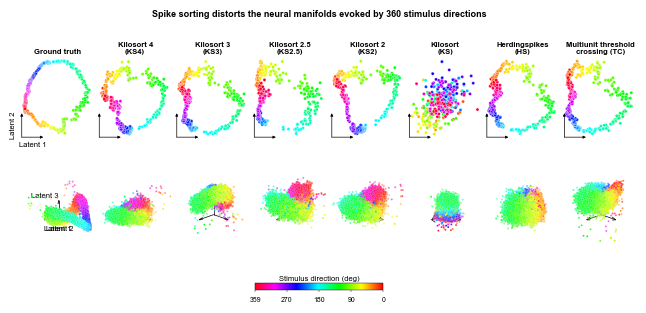

In [5]:
%%time

# plot
fig = plot_source_data(df_3d, df_2d)

# save figure
os.makedirs("figures/8_source_data/fig7a", exist_ok=True)
plt.savefig("figures/8_source_data/fig7a/fig7a.svg", bbox_inches="tight", **savefig_cfg)

# save source data (sheet 1: 3D manifolds of the trials; sheet 2: 2D manifolds, average of the trials of each direction)
with pd.ExcelWriter("figures/8_source_data/fig7a/fig7a.xlsx") as writer:
    df_3d.to_excel(writer, sheet_name="manifold_3d_trials", index=False)
    df_2d.to_excel(writer, sheet_name="manifold_2d_centroids", index=False)

## Check: replot from the saved source data

CPU times: user 3.83 s, sys: 21 ms, total: 3.85 s
Wall time: 3.85 s


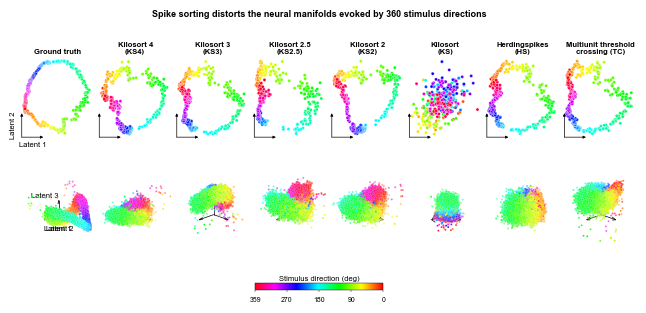

In [6]:
%%time

df_3d = pd.read_excel("figures/8_source_data/fig7a/fig7a.xlsx", sheet_name="manifold_3d_trials")
df_2d = pd.read_excel("figures/8_source_data/fig7a/fig7a.xlsx", sheet_name="manifold_2d_centroids")
fig = plot_source_data(df_3d, df_2d)